# Three bases for the same beam: monomials, cosines and finite elements

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 6, Section "Choosing a Basis: Orthogonality and Conditioning", Example "Three Bases for the Tapered
Cantilever".

A cantilever of unit length, clamped at $x = 0$ and free at $x = 1$, has bending stiffness
$EI(x) = \tfrac{3}{2} - x$ and carries a uniform load $p = 1$. The Galerkin (Ritz) method minimizes the energy
$$\mathcal{E}(w) = \int_0^1 \Big( \tfrac{1}{2}\, EI\, (w'')^2 - p\, w \Big)\, dx, \qquad w(0) = w'(0) = 0,$$
over the span of $N$ trial functions $\varphi_1, \dots, \varphi_N$, by solving
$$\mathbf{K}\mathbf{U} = \mathbf{f}, \qquad K_{ij} = \int_0^1 EI\, \varphi_i''\, \varphi_j''\, dx, \qquad
  f_i = \int_0^1 p\, \varphi_i\, dx .$$
The beam is statically determinate: the bending moment is $M = \tfrac{1}{2}p(1-x)^2$ whatever the stiffness, so
the exact energy $\mathcal{E}(w) = -\tfrac{1}{2}\int_0^1 M^2/EI\, dx$ is known, and the relative error in the
energy norm of an approximation $w_h$ follows from its energy alone:
$$\frac{\|w - w_h\|_a}{\|w\|_a} = \sqrt{\frac{\mathcal{E}(w_h) - \mathcal{E}(w)}{-\mathcal{E}(w)}} .$$

The **same** problem is solved with three bases:
1. the monomials $x^2, x^3, \dots, x^{N+1}$;
2. the functions $1 - \cos(a_k x)$, $a_k = (2k-1)\pi/2$, whose curvatures are mutually orthogonal cosines;
3. the Hermite cubic finite elements of Section 6.3.2: displacement and rotation at the nodes of a uniform mesh,
   two unknowns per node.

For each of them we watch two numbers as $N$ grows: the energy error, and the condition number $\kappa(\mathbf{K})$,
which measures how many digits the computer loses in solving the linear system.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell and run everything again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- PARAMETERS
EI0, EI1 = 1.5, 1.0          # bending stiffness EI(x) = EI0 - EI1 * x  (EI1 = 0: uniform beam)
p        = 1.0               # uniform load
N_mono   = range(1, 19)      # numbers of monomials
N_cos    = [1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 30, 40]   # numbers of cosine functions
Ne_herm  = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]            # numbers of Hermite elements (N = 2 Ne unknowns)
N_show   = 6                 # number of unknowns of the approximations plotted at the end
# ---------------------------------------------------------------------------

## 1. Ingredients

Every integral is computed with Gauss–Legendre quadrature on a subdivision of $(0, 1)$ into `nq` intervals of 16
points each. Each basis function is stored through its values and its curvature at the quadrature points, which
is all that $\mathbf{K}$ and $\mathbf{f}$ need. The same function `galerkin` then serves the three bases.

Besides $\kappa(\mathbf{K})$ we also print the condition number of the *diagonally scaled* matrix
$\mathbf{D}^{-1/2}\mathbf{K}\mathbf{D}^{-1/2}$, $\mathbf{D} = \mathrm{diag}(\mathbf{K})$, which is what we get by
normalizing every basis function in energy, $\varphi_i \to \varphi_i / \sqrt{a(\varphi_i, \varphi_i)}$. This
rescaling costs nothing, and removes the part of the ill-conditioning that is only due to the different sizes of
the basis functions.

In [2]:
def quadrature(nq, n=16):
    """Gauss-Legendre points and weights on (0,1) divided into nq equal intervals."""
    g, wg = np.polynomial.legendre.leggauss(n)
    x = np.concatenate([(e + (g + 1) / 2) / nq for e in range(nq)])
    return x, np.concatenate([wg / 2 / nq] * nq)

EI = lambda x: EI0 - EI1 * x
xq, wq = quadrature(600)          # 600 is a multiple of every number of elements used below
E_exact = -0.5 * np.sum(wq * (0.5 * p * (1 - xq)**2)**2 / EI(xq))

def galerkin(phi, d2):
    """phi, d2: arrays (N, number of points) with the basis functions and their curvatures."""
    K = (d2 * EI(xq) * wq) @ d2.T
    f = (phi * p) @ wq
    U = np.linalg.solve(K, f)
    E = -0.5 * U @ f                                   # energy at the minimum = -1/2 (work of the load)
    err = np.sqrt(max(E - E_exact, 0.0) / -E_exact)    # round-off can make E - E_exact slightly negative
    d = 1 / np.sqrt(np.diag(K))
    return err, np.linalg.cond(K), np.linalg.cond(K * d[:, None] * d[None, :]), U

print(f"exact energy = {E_exact:.10f}")

exact energy = -0.0189995752


## 2. The three bases

**Monomials.** $\varphi_k = x^{k+1}$, $k = 1, \dots, N$, satisfy $w(0) = w'(0) = 0$.

**Cosines.** $\varphi_k = 1 - \cos(a_k x)$ with $a_k = (2k-1)\pi/2$ also satisfy both clamp conditions, and their
curvatures $\varphi_k'' = a_k^2 \cos(a_k x)$ are mutually orthogonal on $(0, 1)$: for a uniform beam the stiffness
matrix would be diagonal. They are *not* the vibration modes of the cantilever (those are studied in Section 6.2).

**Hermite cubics.** On each element of length $h$, with $s = (x - x_e)/h$, the four shape functions
$$N_1 = 1 - 3s^2 + 2s^3,\quad N_2 = h(s - 2s^2 + s^3),\quad N_3 = 3s^2 - 2s^3,\quad N_4 = h(s^3 - s^2)$$
multiply the displacement and the rotation at the left node and at the right node. Two neighbouring elements share
the displacement and the rotation of their common node, so the global functions are continuous with their first
derivative, as the bending energy requires. The clamp removes the two unknowns of the node $x = 0$.

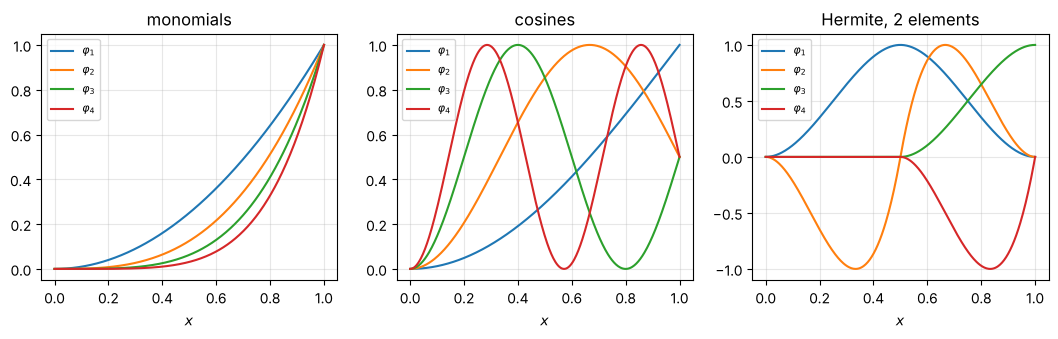

In [3]:
def monomials(N, x):
    k = np.arange(2, N + 2)[:, None]
    return x**k, k * (k - 1) * x**(k - 2), k * (k - 1) * (k - 2) * x**np.maximum(k - 3, 0)

def cosines(N, x):
    a = (2 * np.arange(1, N + 1) - 1)[:, None] * np.pi / 2
    return 1 - np.cos(a * x), a**2 * np.cos(a * x), -a**3 * np.sin(a * x)

def hermite(Ne, x):
    h = 1 / Ne
    e = np.minimum((x / h).astype(int), Ne - 1); s = x / h - e
    shapes = [1 - 3*s**2 + 2*s**3, h*(s - 2*s**2 + s**3), 3*s**2 - 2*s**3, h*(s**3 - s**2)]
    curv   = [(-6 + 12*s) / h**2, (-4 + 6*s) / h, (6 - 12*s) / h**2, (6*s - 2) / h]
    third  = [12 / h**3 + 0*s, 6 / h**2 + 0*s, -12 / h**3 + 0*s, 6 / h**2 + 0*s]
    phi = np.zeros((2 * (Ne + 1), x.size)); d2 = np.zeros_like(phi); d3 = np.zeros_like(phi)
    cols = np.arange(x.size)
    for j in range(4):
        np.add.at(phi, (2 * e + j, cols), shapes[j]); np.add.at(d2, (2 * e + j, cols), curv[j])
        np.add.at(d3, (2 * e + j, cols), third[j])
    return phi[2:], d2[2:], d3[2:]  # drop displacement and rotation of the clamped node

fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
xs = np.linspace(0, 1, 400)
for ax, (name, basis, n) in zip(axs, [("monomials", monomials, 4), ("cosines", cosines, 4),
                                       ("Hermite, 2 elements", hermite, 2)]):
    phi = basis(n, xs)[0]
    for k, ph in enumerate(phi):
        ax.plot(xs, ph / np.max(np.abs(ph)), label=f"$\\varphi_{k+1}$")
    ax.set_title(name); ax.set_xlabel("$x$"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

The four monomials look alike: they all start flat and bend upwards, more and more steeply. The cosines oscillate
faster and faster. The Hermite functions live on one or two elements each.

## 3. Error and conditioning


monomials
   N   energy error   kappa(K)   kappa(scaled K)
   1     5.19e-01    1.00e+00    1.00e+00
   2     5.63e-02    1.33e+01    1.10e+01
   3     1.54e-02    2.27e+02    1.98e+02
   4     4.15e-03    5.17e+03    4.73e+03
   5     1.12e-03    1.34e+05    1.28e+05
   6     3.01e-04    3.73e+06    3.66e+06
   7     8.09e-05    1.08e+08    1.09e+08
   8     2.17e-05    3.24e+09    3.32e+09
   9     5.83e-06    9.88e+10    1.03e+11
  10     1.57e-06    3.06e+12    3.23e+12
  11     4.18e-07    9.58e+13    1.02e+14
  12     1.16e-07    2.95e+15    3.26e+15
  13     1.58e-07    1.43e+17    5.78e+16
  14     8.11e-08    8.22e+17    1.20e+17
  15     0.00e+00    7.03e+16    6.87e+16
  16     0.00e+00    7.52e+16    8.56e+16
  17     0.00e+00    4.00e+16    3.62e+16
  18     0.00e+00    5.01e+16    3.78e+16

cosines
   N   energy error   kappa(K)   kappa(scaled K)
   1     2.25e-01    1.00e+00    1.00e+00
   2     5.99e-02    7.13e+01    1.45e+00
   3     4.47e-02    5.46e+02    1.73e+00


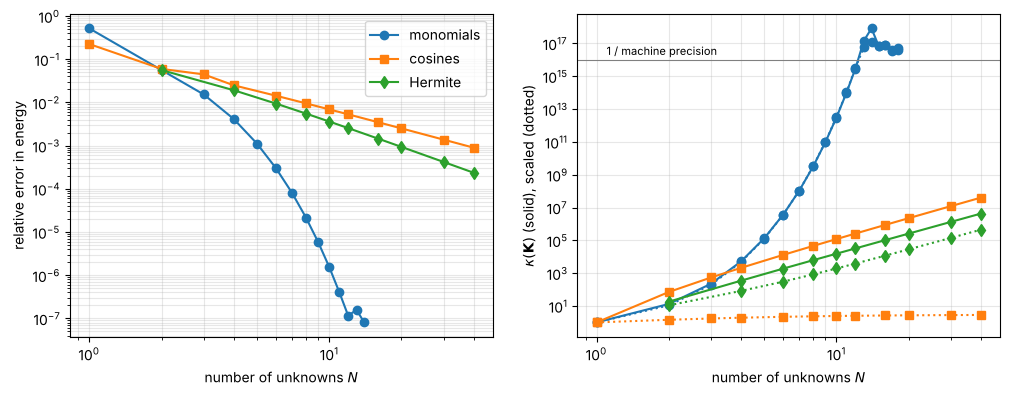

In [4]:
res = {"monomials": [(N, *galerkin(*monomials(N, xq)[:2])[:3]) for N in N_mono],
       "cosines":   [(N, *galerkin(*cosines(N, xq)[:2])[:3]) for N in N_cos],
       "Hermite":   [(2 * Ne, *galerkin(*hermite(Ne, xq)[:2])[:3]) for Ne in Ne_herm]}

for name, rows in res.items():
    print(f"\n{name}\n   N   energy error   kappa(K)   kappa(scaled K)")
    for N, err, k, ks in rows:
        print(f"{N:4d}   {err:10.2e}   {k:9.2e}   {ks:9.2e}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
for (name, rows), m in zip(res.items(), "osd"):
    N, err, k, ks = np.array(rows).T
    good = err > 0
    a1.loglog(N[good], err[good], m + "-", label=name)
    l, = a2.loglog(N, k, m + "-", label=name)
    a2.loglog(N, ks, m + ":", color=l.get_color())
a1.set_xlabel("number of unknowns $N$"); a1.set_ylabel("relative error in energy"); a1.legend()
a2.set_xlabel("number of unknowns $N$"); a2.set_ylabel(r"$\kappa(\mathbf{K})$ (solid), scaled (dotted)")
a2.axhline(1e16, color="gray", lw=0.8); a2.text(1.1, 2e16, "1 / machine precision", fontsize=8)
for a in (a1, a2): a.grid(True, which="both", alpha=0.3)
plt.show()

Three behaviours, one problem.

* **Monomials** are by far the fastest: each new function divides the error by about four, because the exact
  solution is analytic. But they are nearly parallel, and $\kappa(\mathbf{K})$ grows exponentially, by a factor of
  about thirty per function. Around $N = 12$ it reaches $10^{16}$, the inverse of the machine precision, and the
  error stops decreasing near $10^{-7}$: what the new functions add is round-off. Scaling the diagonal does not
  help.
* **Cosines** are well conditioned: $\kappa(\mathbf{K})$ grows only like $N^4$, and the diagonal scaling brings it
  down to about 3, whatever $N$. Yet they converge slowly, more slowly than the finite elements. The reason is
  mechanical, and is examined in the next section of the notebook: the cosines cannot represent the shear force
  at the clamp.
* **Hermite elements** converge like $h^2 \sim N^{-2}$, slowly but steadily. $\kappa(\mathbf{K})$ grows like $N^4$,
  and the diagonal scaling gains only a constant factor: the growth comes from the fourth-order operator, which
  amplifies the short wavelengths that a fine mesh can represent, not from the basis. With a bandwidth of four,
  these matrices remain cheap to solve for millions of unknowns.

## 4. Bending moment and shear force

The Galerkin method minimizes the energy, so it is the bending moment $M_h = EI\, w_h''$, which enters the energy,
that is approximated best; the shear force $T_h = -M_h'$ is one derivative further away.

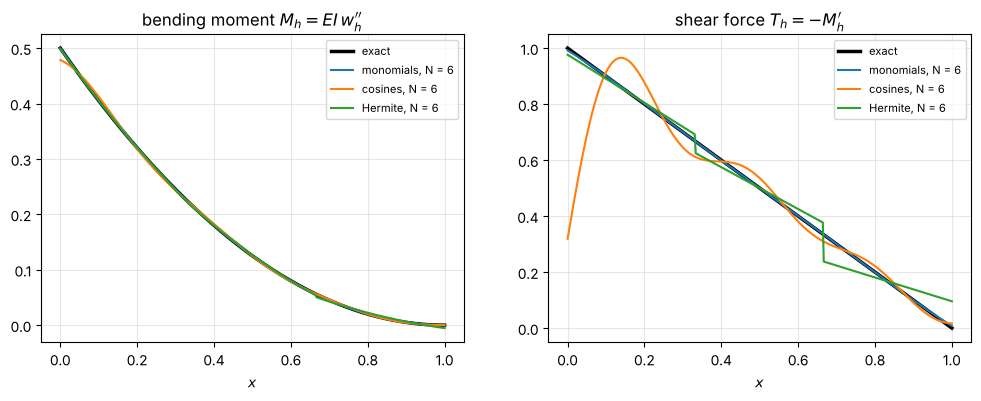

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
M_ex = 0.5 * p * (1 - xs)**2
a1.plot(xs, M_ex, "k", lw=2.5, label="exact"); a2.plot(xs, p * (1 - xs), "k", lw=2.5, label="exact")
for name, basis, n in [("monomials", monomials, N_show), ("cosines", cosines, N_show),
                       ("Hermite", hermite, N_show // 2)]:
    U = galerkin(*basis(n, xq)[:2])[3]
    phi, d2, d3 = basis(n, xs)
    M = EI(xs) * (U @ d2)                              # M = EI w''
    T = EI1 * (U @ d2) - EI(xs) * (U @ d3)             # T = -M' = -(EI w'')'
    a1.plot(xs, M, label=f"{name}, N = {len(U)}")
    a2.plot(xs, T, label=f"{name}, N = {len(U)}")
a1.set_title("bending moment $M_h = EI\\, w_h''$"); a2.set_title("shear force $T_h = -M_h'$")
for a in (a1, a2): a.set_xlabel("$x$"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.show()

The moments are all close to the exact parabola. The shear forces are not. Every cosine curvature
$a_k^2\cos(a_k x)$ has zero slope at $x = 0$, so **every** combination of cosines has $w_h'''(0) = 0$. The shear
force at the clamp is then $T_h(0) = -(EI\,w_h'')'(0) = EI_1\, w_h''(0)$, only the part due to the taper: about
one third of the exact value $pL = 1$, and exactly zero for a uniform beam. The basis violates a property of the
solution, and the series must struggle to represent a curvature with a non-zero end slope by functions with zero
end slopes, as a Fourier series struggles near a jump: the error concentrates near the clamp and decays slowly.
The Hermite curvatures are linear on each element, so their shear force is piecewise constant (for a uniform beam;
here it also contains the small term $EI_1 w_h''$), and it jumps at the nodes.

## Things to try
1. Set `EI1 = 0` (uniform beam): the cosine stiffness matrix becomes exactly diagonal, $\kappa$ of the scaled
   matrix is exactly 1, yet the convergence of the cosines is as slow as before. Orthogonality cures the
   conditioning, not the approximation.
2. Extend `N_mono` to 25: beyond $N \approx 14$ the monomial error grows, and may even fail (negative energy
   error, or a warning from the solver).
3. Increase the taper, `EI1 = 1.4`, so that the tip is fifteen times softer than the root: which basis suffers
   most?
4. Give the cosine basis what it lacks, a shear force at the clamp: add to it the single function $x^2(3 - x)$,
   the deflection of a cantilever under a tip force. How much does the cosine error improve?
5. Compute the tip deflection $w_h(1)$ for the three bases and compare with the error in energy: does the tip
   deflection always improve when the energy does?